# Imaging Phenotype Variants Analyses

In [2]:
import sys
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.decomposition import PCA
import pandas as pd
from matplotlib.patches import Patch
from dynamicTreeCut import cutreeHybrid
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import matplotlib.font_manager as fm
from scipy.spatial.distance import pdist
# from utils import inverse_normal_transform
# from adjustText import adjust_text
# from sklearn.metrics import silhouette_score
# from matplotlib.colors import ListedColormap
# from matplotlib.ticker import FixedFormatter

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})
sns.set_theme(style='white')

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from utils import IMG_PHENO_VAR_REF_SC_PROFILE_PQ

FEATURE_IMPORTANCE_THRES = 0.01
SIGNALING_DOMAINS = [
    "g2p_Signal (UniProt)",
    "g2p_Transit peptide (UniProt)",
    "g2p_Transmembrane (UniProt)",
    "g2p_Topological domain (UniProt)",
    "g2p_Intramembrane (UniProt)",
    "g2p_Lipidation (UniProt)"
]
META_COLS = [
    "gene_variant",
    "Metadata_Bio_Batch",
    "img_pheno_score",
    "img_misloc_score",
    "img_pheno_hit",
    "img_misloc_hit",
    "clinvar_clnsig_clean",
    "clinvar_clnsig_clean_pp_strict",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
    "disease_modules",
    "inheritance_pattern",
    "plddt_f32",
    "rsa_f32", 
    "pLDDT_Category",
    "RSA_Category",
] + SIGNALING_DOMAINS

## 1. Loading data

In [3]:
ref_var_cell_all_prof_df = pl.read_parquet(IMG_PHENO_VAR_REF_SC_PROFILE_PQ)
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

In [4]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/0_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("img_pheno_hit"),
)
pheno_alleles = imaging_summary_clinvar_hits["gene_variant"].to_list()
print("Imaging phenotype alleles:", len(pheno_alleles))

## Protein abundance change
# imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
#     (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
# )
# prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_variant"].to_list()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()
imaging_summary_clinvar_hits

Imaging phenotype alleles: 128


Gene,gene_variant,Bio_Batch,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_cc_t_pval_fdr_bh_adj,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,U2OS_prot_abun_t_pval_fdr_bh_adj,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,…,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,img_pheno_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict
str,str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,f64,bool,bool,bool
"""SFTPC""","""SFTPC_Leu188Gln""","""B_7-8""",-3.268894,0.017058,0.040573,7.219706,0.000358,0.001061,"""2024_01_Batch_7-8""",true,true,false,false,false,false,false,false,false,false,false,false,0.969708,0.963825,0.733094,0.707901,0.712487,0.747324,0.918914,0.861085,0.913191,0.896478,0.978869,0.966044,0.575735,0.563889,0.502612,…,null,"""Propeptide""",null,null,null,null,"""dbSNP: rs121917835; Variant ty…",null,null,null,"""Helix""",null,null,null,null,null,null,null,null,null,null,90.06,12.195122,""">90""","""10-90""","""610913""","""autosomal dominant""","""OMIM""","""Rare genetic respiratory disea…",1,"""SURFACTANT METABOLISM DYSFUNCT…",false,0.963825,0.969708,true,true,false
"""GFAP""","""GFAP_Asn77Ser""","""B_15-16""",0.602116,0.566081,0.644348,11.461787,0.000009,0.00007,"""2025_03_Batch_15-16""",true,true,false,false,false,false,true,false,false,false,false,false,0.979233,0.968505,0.589523,0.814242,0.868859,0.71119,0.612648,0.869974,0.734454,0.582658,0.960269,0.97184,0.809732,0.867744,0.89403,…,"""Pocket 5: Mean pLDDT: 80.91, V…",null,-39.8,"""Coil 1A""",null,null,"""dbSNP: rs58732244; Variant typ…",null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,90.75,62.42038,""">90""","""10-90""","""203450""","""autosomal dominant""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""ALEXANDER DISEASE""",false,0.968505,0.979233,true,true,false
"""PLP1""","""PLP1_Gly186Cys""","""B_7-8""",-0.279086,0.791354,0.835075,1.969815,0.096375,0.128058,"""2024_01_Batch_7-8""",true,true,false,false,false,false,false,false,false,false,false,false,0.974526,0.977719,0.705859,0.709964,0.655547,0.851982,0.851982,0.626048,0.827843,0.803025,0.982001,0.970311,null,0.685047,0.592084,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,87.14,5.952381,"""70-90""","""<10""",null,"""unknown""",null,"""Rare genetic eye disease; Rare…",2,null,false,0.977719,0.974526,true,true,false
"""DCX"""

## 2. Imaging Phenotype Variants

In [5]:
# TOP_NUM_FEAT_MISLOC_VAR = 5
# # Get top 10 for each variant with feature names
# top_feat_misloc_alleles = []
# for col in misloc_alleles:
#     top_feats = feat_df.filter(
#         pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
#     ).select(["cp_feature", col])
#     # print(top_feats.sort(col))
#     top_feat_misloc_alleles.append(top_feats)
    
# # Start with all features and left join each variant's top 10
# result_df = feat_df.select("cp_feature").unique().sort("cp_feature")
# for i, col in enumerate(misloc_alleles):
#     result_df = result_df.join(top_feat_misloc_alleles[i], on="cp_feature", how="left")

# misloc_var_top10_feat_df = result_df.select(
#     ["cp_feature"] + pheno_alleles
# ).filter(
#     ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
# )
# get_top_n_feats_misloc_alleles = misloc_var_top10_feat_df["cp_feature"].to_list()
# len(get_top_n_feats_misloc_alleles)

In [5]:
pheno_var_sig_feat_df = feat_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(pheno_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_pheno_alleles = pheno_var_sig_feat_df["cp_feature"].to_list()

### 2.1 Calculate Z-score for phenotypic directional change

In [6]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_pheno_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_vars_feat_df = pl.concat(
        [norm_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 38/38 [00:09<00:00,  4.21it/s]


### 2.2 Feature selection

In [7]:
## This is already a Z-scored feature matrix, no extra processing is needed
var_zscore_feat_gfp_filtered_int_df = norm_vars_feat_df.to_pandas()#.set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping). NOT NEEDED
# We clip values at -5 (lower) and +5 (upper)
# var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

## Append important medadata to data frame
var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(META_COLS).rename(
        {k: f"Metadata_{k}" for k in META_COLS if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]

### 2.3 Dimension reduction and clustering

In [8]:
# ----------------------------------------------------------------------
# 1. Robust PCA
# ----------------------------------------------------------------------
# Dynamic component selection: Keep 90% of variance
pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)
n_pcs = data_pca.shape[1]
print(f"PCA retained {n_pcs} components explaining 90% variance.")

# Create PCA DataFrame dynamically
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]
pca_df = pd.DataFrame(data_pca, columns=pca_cols)
# Safely attach metadata using index alignment
pca_df = pd.concat([df_meta[metadata_cols].reset_index(drop=True), pca_df], axis=1)

PCA retained 9 components explaining 90% variance.


Minimum cluster size: 6
..cutHeight not given, setting it to 36.59149968646403  ===>  99% of the (truncated) height range in dendro.
..done.


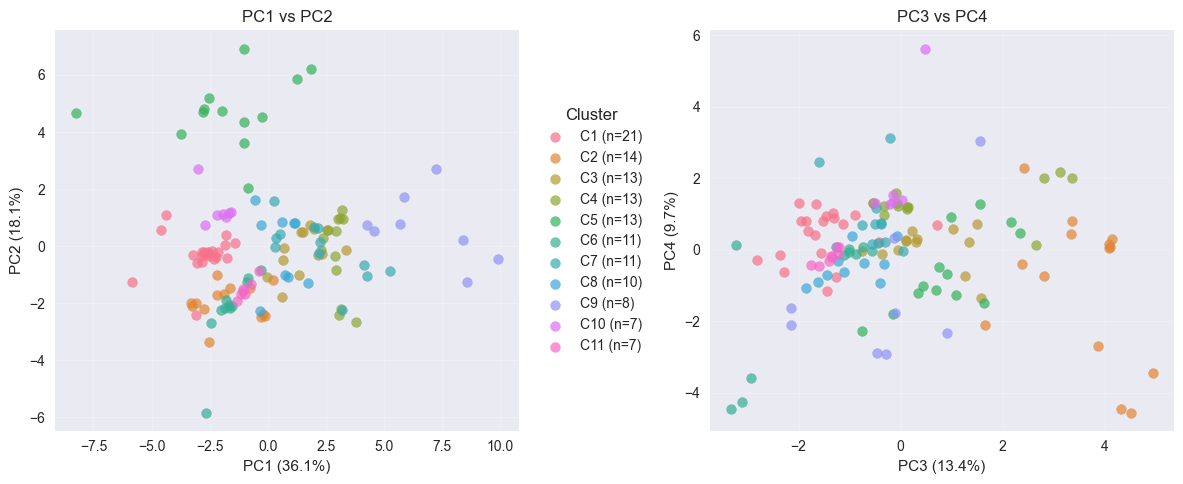

In [9]:
# ----------------------------------------------------------------------
# 2. Hierarchical Clustering on PCA
# ----------------------------------------------------------------------
Z = linkage(data_pca, method='ward', metric='euclidean')
dist_matrix = pdist(data_pca, metric='euclidean')
linkage_matrix_pca = linkage(data_pca, method='ward', optimal_ordering=True)

# Dynamic tree cut - adapts to tree structure with minimum cluster size
# minClusterSize: minimum number of samples per cluster (key parameter)
min_cluster_size = max(5, len(data_pca) // 20)
print(f"Minimum cluster size: {min_cluster_size}")

cluster_labels = cutreeHybrid(
    Z,
    dist_matrix,
    minClusterSize=min_cluster_size,
    deepSplit=2,
)["labels"]

n_clusters = len(set(cluster_labels))
colors = sns.color_palette("husl", n_clusters)
unique_labels = sorted(np.unique(cluster_labels))
color_map = {label: colors[i] for i, label in enumerate(unique_labels)}

# ----------------------------------------------------------------------
# 3. Plot 1: PCA Scatter (PC1/PC2 and PC3/PC4)
# ----------------------------------------------------------------------
n_pcs = data_pca.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# PC1 vs PC2
for c in unique_labels:
    mask = cluster_labels == c
    axes[0].scatter(
        data_pca[mask, 0], 
        data_pca[mask, 1],
        c=[color_map[c]], 
        label=f'C{c} (n={mask.sum()})',
        alpha=0.7,
        s=50
    )
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PC1 vs PC2')
axes[0].legend(bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=10, title="Cluster")
axes[0].grid(alpha=0.2)

# PC3 vs PC4
if n_pcs >= 4:
    for c in unique_labels:
        mask = cluster_labels == c
        axes[1].scatter(
            data_pca[mask, 2], 
            data_pca[mask, 3],
            c=[color_map[c]], 
            label=f'C{c} (n={mask.sum()})',
            alpha=0.7,
            s=50
        )
    axes[1].set_xlabel(f'PC3 ({pca.explained_variance_ratio_[2]:.1%})')
    axes[1].set_ylabel(f'PC4 ({pca.explained_variance_ratio_[3]:.1%})')
    axes[1].set_title('PC3 vs PC4')
    axes[1].grid(alpha=0.2)
else:
    axes[1].text(0.5, 0.5, f'Only {n_pcs} PCs available', ha='center', va='center')
    axes[1].set_title('PC3 vs PC4 (unavailable)')

plt.tight_layout()
plt.show()

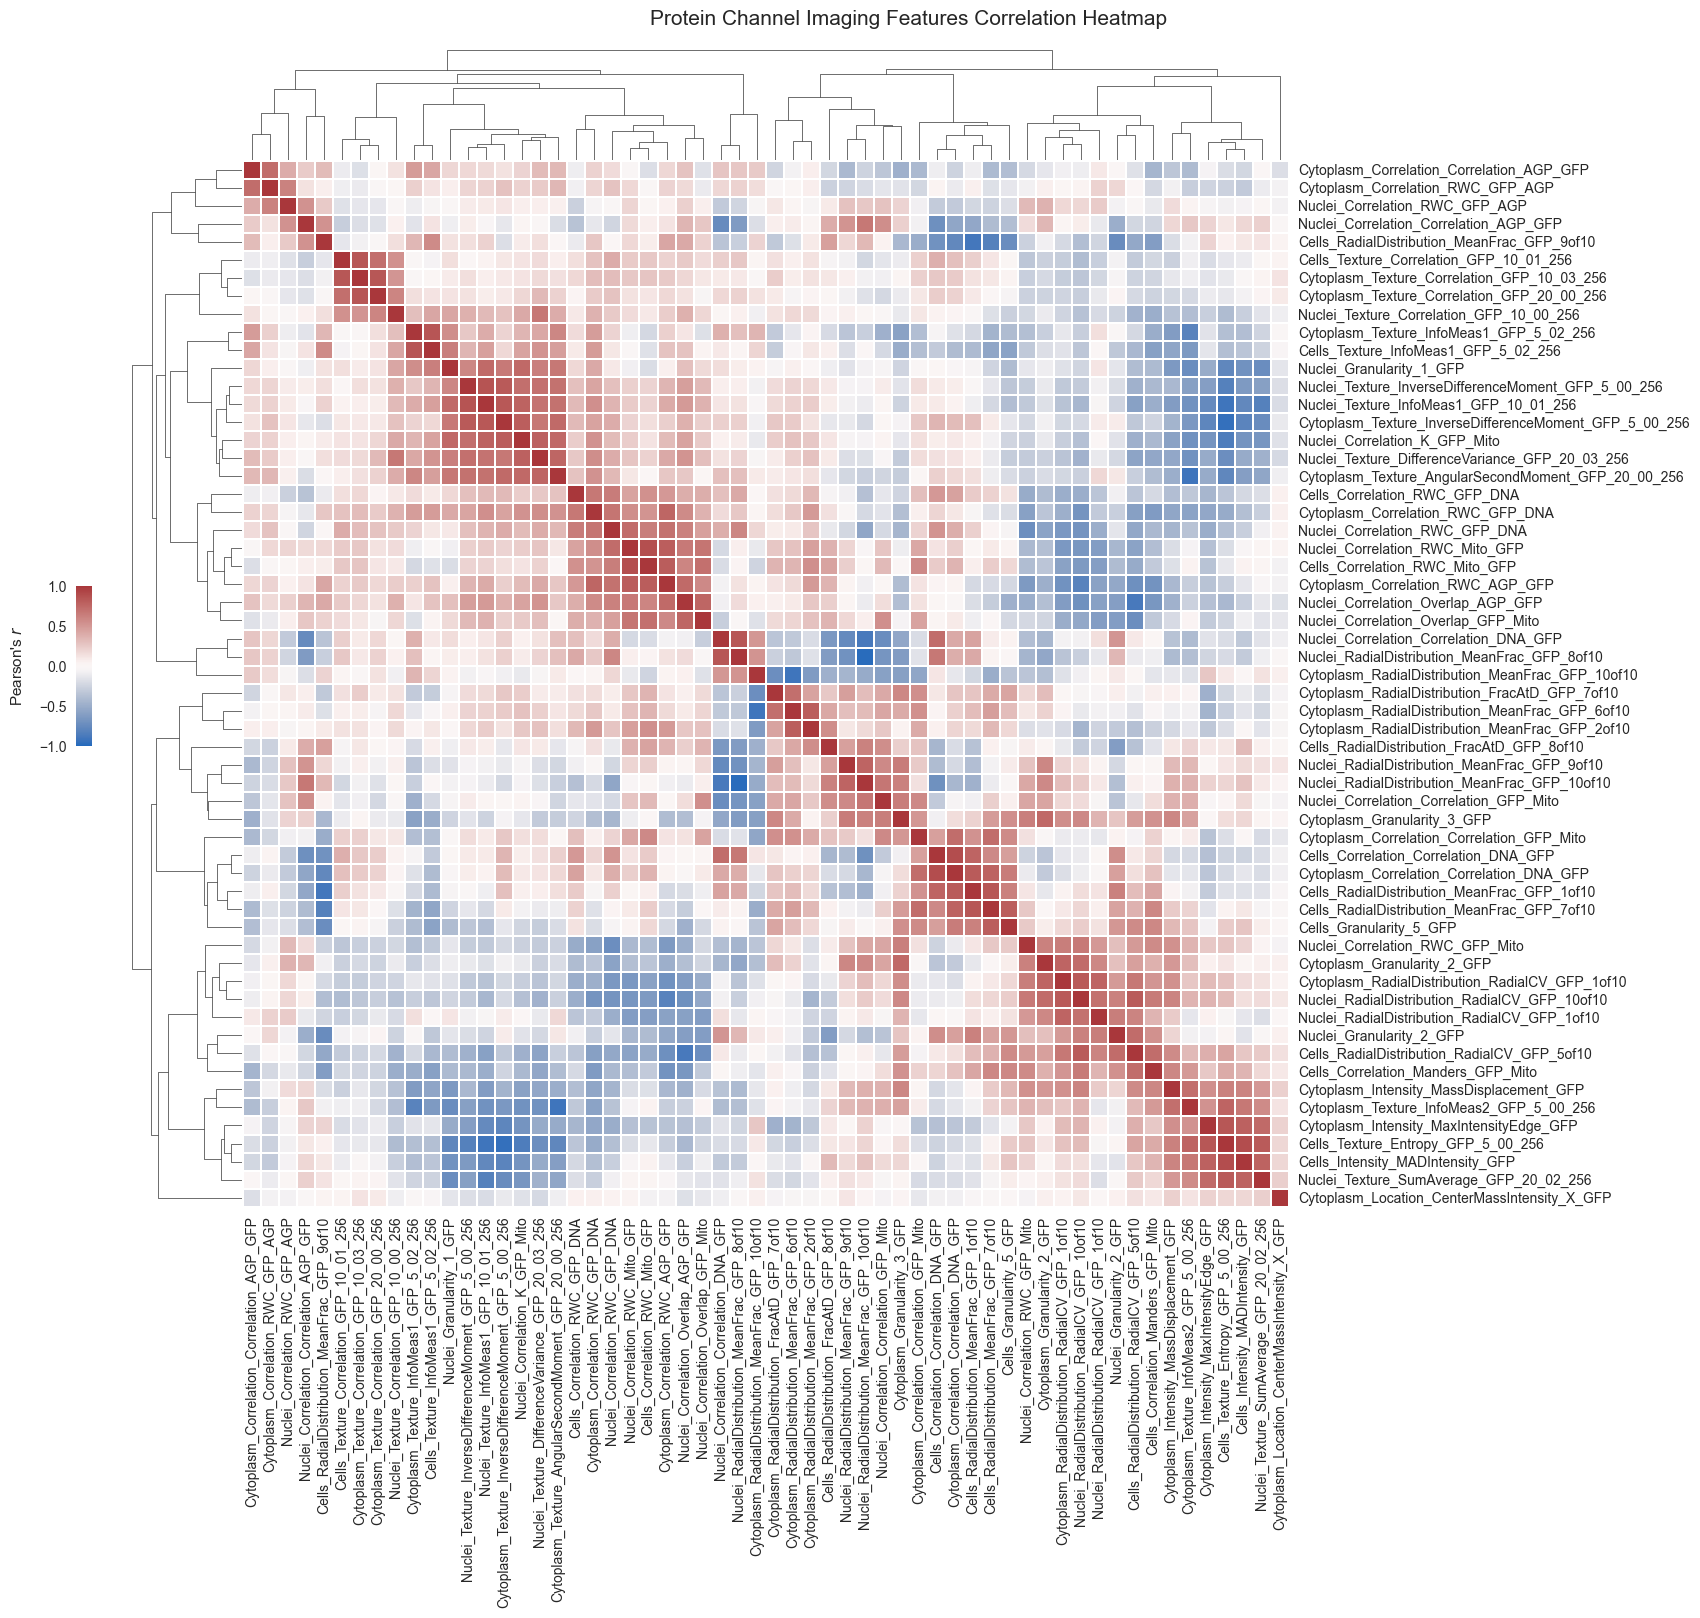

In [10]:
# Correlation clustermap (run first to get column linkage)
# Correlation clustermap with optimal leaf ordering
corr_df = df.corr()

# Convert correlation to distance (1 - r), then to condensed form
corr_dist = 1 - corr_df.values
np.fill_diagonal(corr_dist, 0)  # Ensure diagonal is 0
corr_dist_condensed = squareform(corr_dist)

# Compute linkage with optimal ordering
col_linkage = linkage(corr_dist_condensed, method='average', optimal_ordering=True)

g_corr = sns.clustermap(
    data=corr_df,
    cmap="vlag", vmin=-1,
    row_linkage=col_linkage,
    col_linkage=col_linkage,
    cbar_pos=(-.02, 0.55, 0.01, 0.1),
    yticklabels=1, xticklabels=1,
    # square=True,
    figsize=(16, 16),
    linewidth=.05,
    dendrogram_ratio=(0.1, 0.1),
    
)
g_corr.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g_corr.cax.yaxis.set_label_position('left')
g_corr.cax.yaxis.set_ticks_position('left')
g_corr.cax.set_ylabel(r"Pearson's $r$", labelpad=10)
g_corr.ax_heatmap.set_xticklabels(g_corr.ax_heatmap.get_xticklabels(), fontsize=10)
g_corr.ax_heatmap.set_yticklabels(g_corr.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

# Extract column linkage and order
col_order = list(corr_df.columns[g_corr.dendrogram_col.reordered_ind])

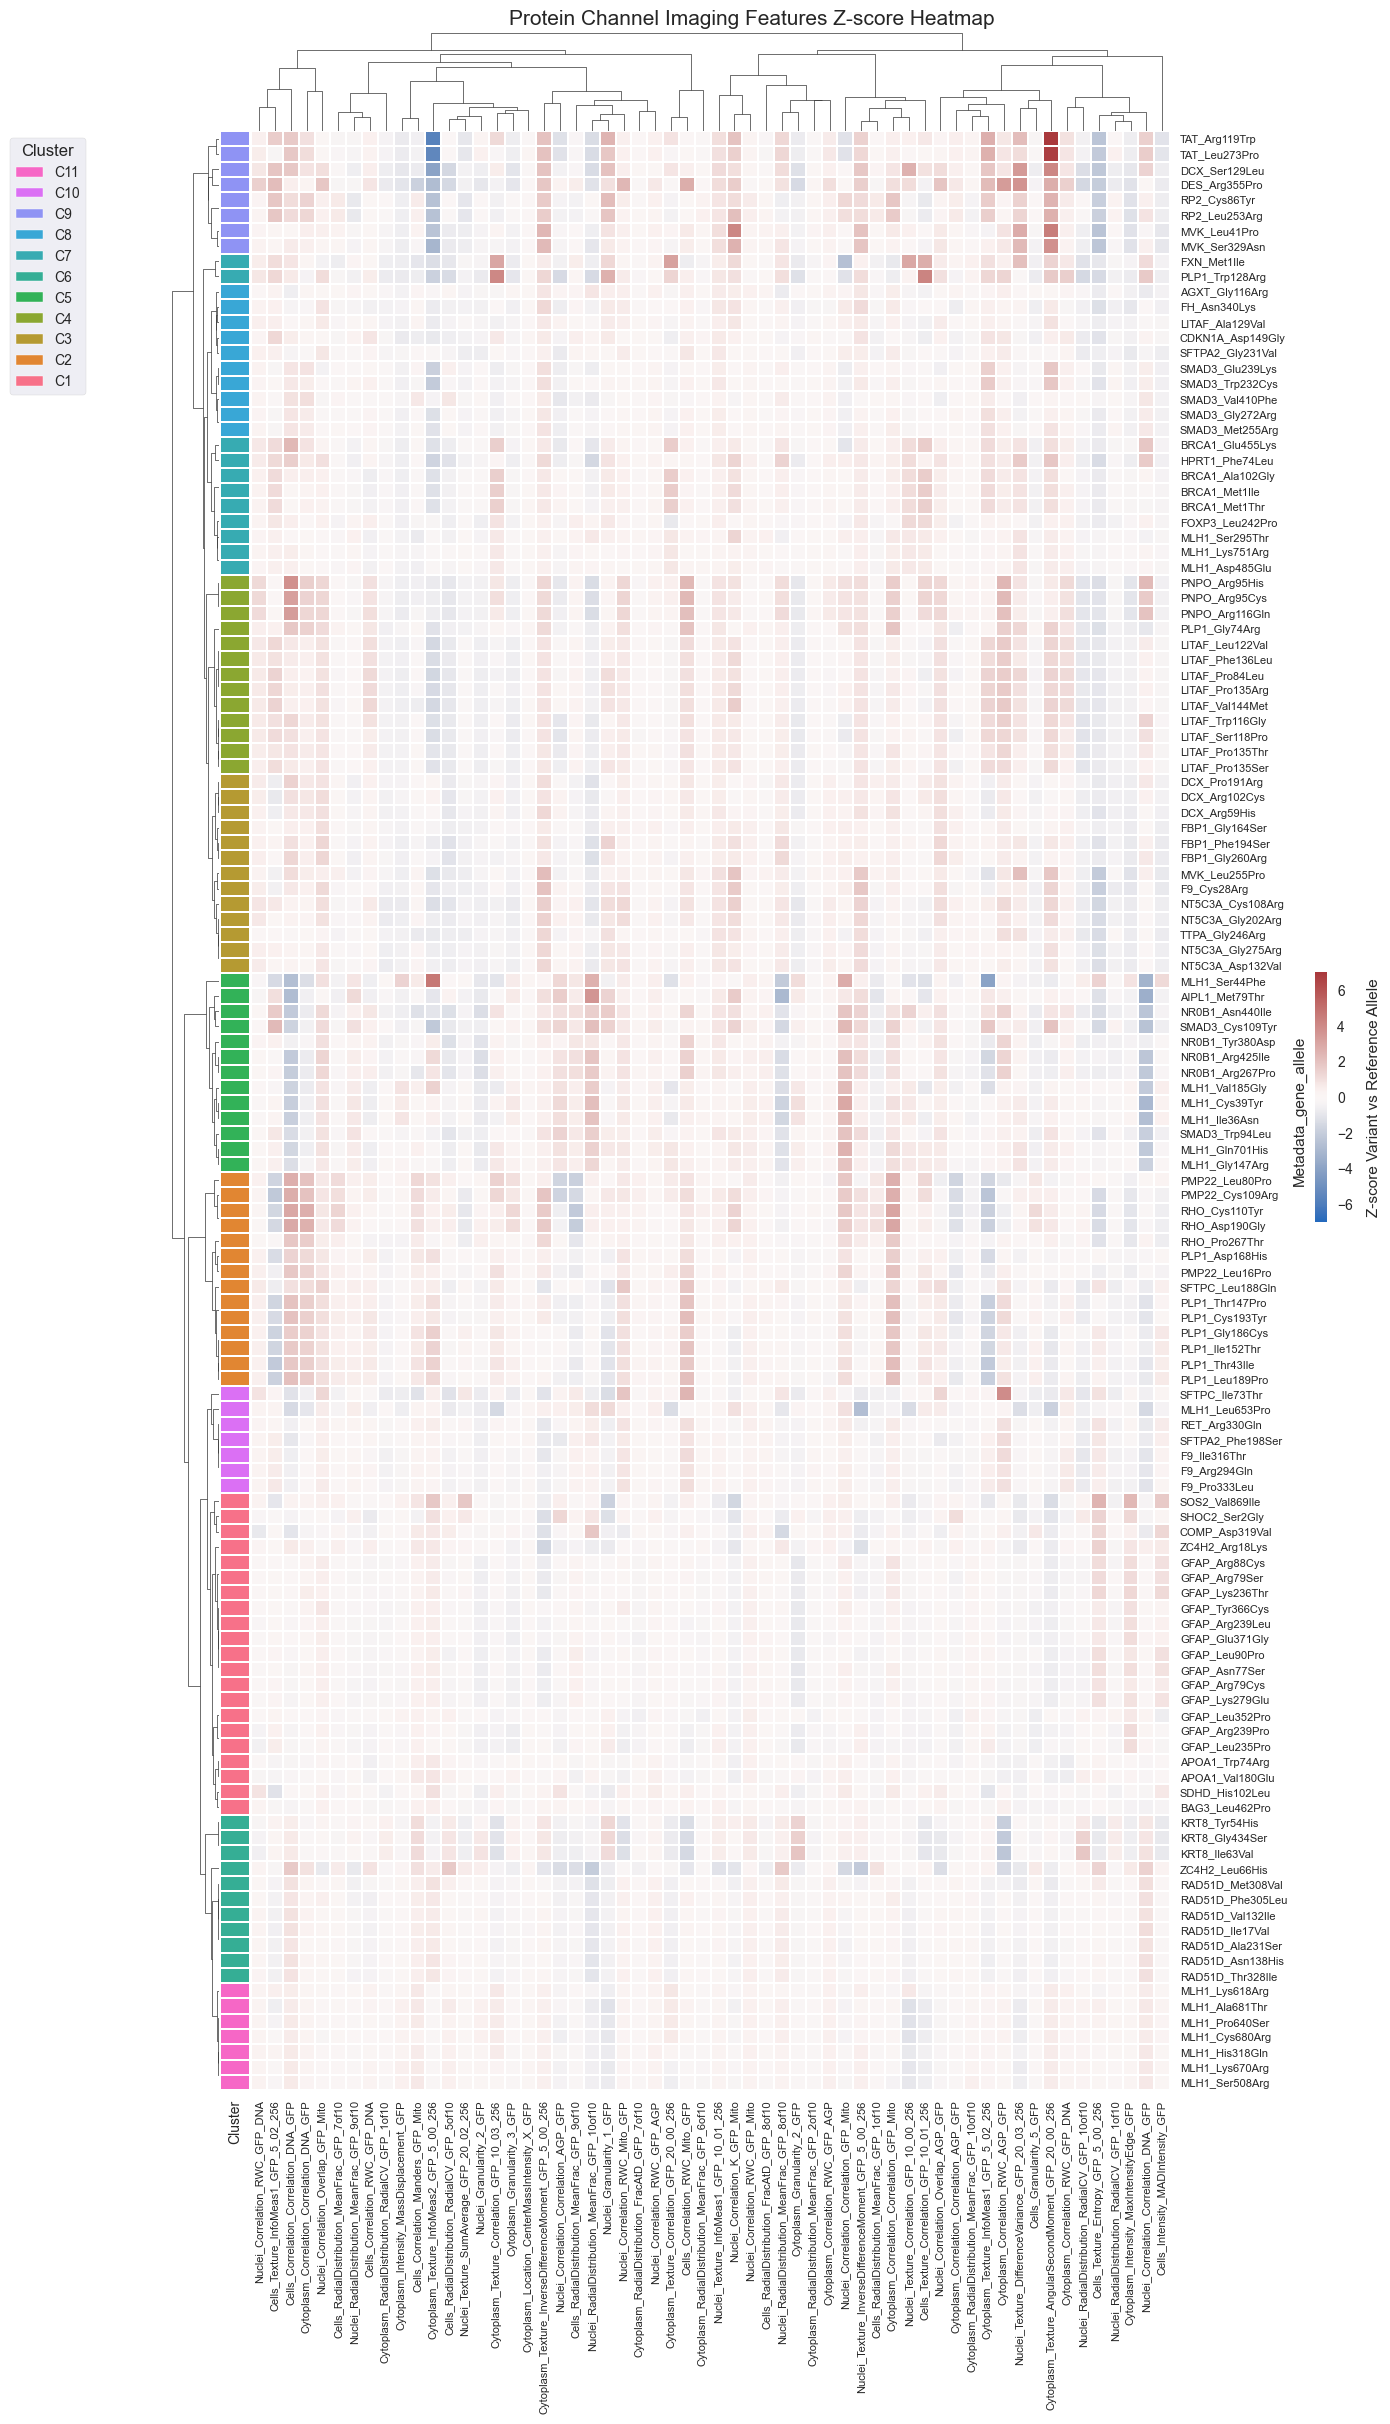

In [11]:
# ----------------------------------------------------------------------
# 4. Plot 2: Clustermap with PCA-based Dendrogram
# ----------------------------------------------------------------------
# Row colors from cluster assignment
row_colors_series = pd.Series(
    [color_map[c] for c in cluster_labels], 
    index=df.index, 
    name='Cluster'
)

# Main clustermap with correlation-based column dendrogram
g = sns.clustermap(
    data=df[col_order],  # Reorder columns to match
    cmap="vlag",
    center=0, vmin=-np.ceil(df[col_order].max().max()), 
    vmax=np.ceil(df[col_order].max().max()),
    row_colors=row_colors_series,
    row_linkage=Z,
    col_linkage=col_linkage,  # Use correlation-based linkage
    figsize=(12, 25),
    yticklabels=1,
    xticklabels=1,
    linewidths=0.05,
    cbar_pos=(.97, 0.515, 0.01, 0.1),
    dendrogram_ratio=(0.05, 0.05)
)

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=8, rotation=90)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=8)
g.cax.set_ylabel(r"Z-score Variant vs Reference Allele", labelpad=10)
g.fig.suptitle("Protein Channel Imaging Features Z-score Heatmap", fontsize=15, y=1)

legend_handles = [Patch(facecolor=color_map[c], label=f'C{c}') 
                  for c in sorted(color_map.keys(), reverse=True)]
g.ax_heatmap.legend(
    handles=legend_handles,
    title='Cluster',
    bbox_to_anchor=(-0.27, 1.0),
    loc='upper left',
    frameon=True
)
plt.show()

In [13]:
# ----------------------------------------------------------------------
# 5. Results DataFrame
# ----------------------------------------------------------------------
dr_res_df = df_meta.copy()
dr_res_df["Metadata_cluster"] = cluster_labels

In [ ]:
# dr_res_df.to_csv("../../3_outputs/3_img_pheno_var_clustering_results.csv")

## 3. Explorative Analyses

In [ ]:
# pleitropy to look at for genes
## Check over-exposure 
## MLH1 PPI cross-check
## GFAP stability of the proteins

In [18]:
cluster_results_df = pl.read_csv("../../3_outputs/3_img_pheno_var_clustering_results.csv")
cluster_analysis_df = pl.read_csv("../../3_outputs/3_img_pheno_var_clustering_analysis_results.csv")
cluster_analysis_df

subcell_loc_df = pl.read_csv("../../1_inputs/subcell_loc/final_merged_subcellular_data.csv")
subcell_loc_df_gene = subcell_loc_df.filter(
    pl.col("HPA_Gene name").is_in(cluster_analysis_df["gene"].unique())
).unique("official_gene_name").sort("official_gene_name")
# with pl.Config(set_tbl_rows=100):
#     display(subcell_loc_df_gene)

### 3.1 Heterogeneous Cluster 4 Annotations

Mislocalization from plasma membrane to cytoplasmic enrichment

In [19]:
with pl.Config(set_tbl_rows=100):
    print(
        cluster_results_df.filter(
            pl.col("Metadata_cluster")==4
        ).sort("Metadata_gene_allele").with_columns(
            pl.col("Metadata_gene_allele").str.split('_').list.get(0).alias("official_gene_name")
        ).join(
            subcell_loc_df_gene,
            on="official_gene_name",
            how="left"
        ).select("Metadata_gene_allele","Metadata_clinvar_clnsig_clean_pp_strict")
        ## ,"official_gene_name","HPA_Main location", "HPA_Additional location", "UniProt_Subcellular location [CC]"
    )

shape: (13, 2)
┌──────────────────────┬─────────────────────────────────┐
│ Metadata_gene_allele ┆ Metadata_clinvar_clnsig_clean_… │
│ ---                  ┆ ---                             │
│ str                  ┆ str                             │
╞══════════════════════╪═════════════════════════════════╡
│ LITAF_Leu122Val      ┆ Pathogenic                      │
│ LITAF_Phe136Leu      ┆ VUS                             │
│ LITAF_Pro135Arg      ┆ VUS                             │
│ LITAF_Pro135Ser      ┆ VUS                             │
│ LITAF_Pro135Thr      ┆ Pathogenic                      │
│ LITAF_Pro84Leu       ┆ VUS                             │
│ LITAF_Ser118Pro      ┆ VUS                             │
│ LITAF_Trp116Gly      ┆ Pathogenic                      │
│ LITAF_Val144Met      ┆ VUS                             │
│ PLP1_Gly74Arg        ┆ Others                          │
│ PNPO_Arg116Gln       ┆ Likely benign                   │
│ PNPO_Arg95Cys        ┆ Likely pathogeni

### 3.2 Gene-dominant cluster

### 3.2.1 LITAF

#### 3.2.1 GFAP

Lacoste et al: GFAP variant localization ranged from reference-like in- termediate filament localization to diffuse cytoplasmic staining to prominent cytoplasmic punctae, likely reflecting pathogenic aggregation66
(Figure 5B). The localization pattern correlated with the age of onset of the disease: the E207Q variant associ- ated with adult-onset disease showed only a partial diffuse local- ization, whereas the R258P variant with the youngest age of onset was localized to distinct punctae.

In [21]:
# cluster_analysis_df.filter(
#     pl.col("gene")=="GFAP"
# )

with pl.Config(set_tbl_rows=100):
    print(
        cluster_analysis_df.filter(
            pl.col("cluster")==4
        )
    )

# with pl.Config(set_tbl_rows=100):
#     print(
#         cluster_results_df.filter(
#             pl.col("Metadata_cluster")==2
#         ).select("Metadata_gene_allele","Metadata_clinvar_clnsig_clean_pp_strict")
#     )

shape: (13, 9)
┌──────────────┬───────┬─────────┬─────────────┬───┬─────────────┬─────────────┬──────────┬────────┐
│ gene_allele  ┆ gene  ┆ cluster ┆ primary_dis ┆ … ┆ cleaned_dis ┆ disease_cou ┆ score    ┆ is_hit │
│ ---          ┆ ---   ┆ ---     ┆ ease_module ┆   ┆ eases       ┆ nt          ┆ ---      ┆ ---    │
│ str          ┆ str   ┆ i64     ┆ ---         ┆   ┆ ---         ┆ ---         ┆ f64      ┆ bool   │
│              ┆       ┆         ┆ str         ┆   ┆ str         ┆ i64         ┆          ┆        │
╞══════════════╪═══════╪═════════╪═════════════╪═══╪═════════════╪═════════════╪══════════╪════════╡
│ LITAF_Pro135 ┆ LITAF ┆ 4       ┆ Rare        ┆ … ┆ CHARCOT-MAR ┆ 1           ┆ 0.954699 ┆ false  │
│ Thr          ┆       ┆         ┆ genetic neu ┆   ┆ IE-TOOTH    ┆             ┆          ┆        │
│              ┆       ┆         ┆ rological   ┆   ┆ DISEASE, D… ┆             ┆          ┆        │
│              ┆       ┆         ┆ diso…       ┆   ┆             ┆          

In [22]:
# fig, axes = plt.subplots(1,2,figsize=(10,6),sharey=True)
# df_plot = pl.DataFrame(dr_res_df.reset_index()).with_columns(
#     (pl.col("Metadata_g2p_Signal (UniProt)")=="Signal").alias("Signal_Peptide"),
#     (pl.col("Metadata_g2p_Transit peptide (UniProt)")=="Mitochondrion").alias("Transit_Peptide"),
#     pl.col("Metadata_gene_allele").alias("gene_variant")    
# ).sort("Metadata_cluster")

# plot_assay_hit_by_category_perc(
#     df_plot, 
#     "Signal_Peptide", "Metadata_cluster", 
#     f"Functional Hit Rate by Any Assay",
#     ax=axes[0]
# )
# plot_assay_hit_by_category_perc(
#     df_plot, 
#     "Transit_Peptide", "Metadata_cluster", 
#     f"Functional Hit Rate by Any Assay",
#     ax=axes[1]
# )
# plt.subplots_adjust(wspace=0.1)
# plt.show()